# Reproducing Gaia2 on a small budget: a verdict-parsing bug in the released judge

Yating Zhu · CS329Z Paper Video, Stanford, Fall 2026

Paper: Froger et al., *Gaia2: Benchmarking LLM Agents on Dynamic and Asynchronous Environments*, ICLR 2026 ([arXiv:2602.11964](https://arxiv.org/abs/2602.11964)). Harness: `meta-agents-research-environments` (ARE) 1.2.0.

| Section | Content |
| --- | --- |
| 1 | Reproduction with the released harness: 10 Execution + 10 Time scenarios from the Gaia2 validation split, Gemini 2.5 Flash and Claude Sonnet 4.5, Llama-3.3-70B judge, one run each |
| 2 | Which checks fail |
| 3 | Cause: the judge's verdict is lower-cased before it is parsed |
| 4 | A two-line fix: Execution traces re-judged, Time scenarios re-run |
| 5 | One two-turn scenario, before and after the fix |
| 6 | Extension: an explicit timing instruction |
| 7 | Cost and export |

Requires two Colab Secrets: `HF_TOKEN` and `OPENROUTER_API_KEY`. Outputs are written to `/content/results/`. A full run takes about three hours.

## Setup

In [ ]:
%%capture --no-stderr
!pip install -q "meta-agents-research-environments==1.2.0" huggingface_hub pandas requests matplotlib

In [ ]:
import os
from google.colab import userdata
from huggingface_hub import login

login(token=userdata.get("HF_TOKEN"), add_to_git_credential=False)
os.environ["OPENROUTER_API_KEY"] = userdata.get("OPENROUTER_API_KEY")

In [ ]:
# Local copy of the simulated file system. Without it, ARE fetches files from the Hub one by one
# and quickly runs into the Hub's rate limit.
from huggingface_hub import snapshot_download

snapshot_download(
    repo_id="meta-agents-research-environments/gaia2_filesystem",
    repo_type="dataset",
    allow_patterns=["demo_filesystem/*", "demo_filesystem/**"],
    local_dir="/content/gaia2_fs",
)
os.environ["DEMO_FS_PATH"] = "/content/gaia2_fs/demo_filesystem"

Fetching 294 files:   0%|          | 0/294 [00:00<?, ?it/s]

demo_filesystem/Documents/benchmarks/rob(…):   0%|          | 0.00/223k [00:00<?, ?B/s]

demo_filesystem/Documents/benchmarks/rob(…):   0%|          | 0.00/99.0 [00:00<?, ?B/s]

demo_filesystem/Documents/benchmarks/rob(…):   0%|          | 0.00/54.0k [00:00<?, ?B/s]

demo_filesystem/Documents/benchmarks/rob(…):   0%|          | 0.00/6.12k [00:00<?, ?B/s]

demo_filesystem/Documents/benchmarks/rob(…):   0%|          | 0.00/5.50k [00:00<?, ?B/s]

... (282 outputs left out)

demo_filesystem/Pictures/Personal/Travel(…):   0%|          | 0.00/2.42M [00:00<?, ?B/s]

demo_filesystem/Pictures/Personal/Travel(…):   0%|          | 0.00/1.97M [00:00<?, ?B/s]

demo_filesystem/Pictures/llama.jpg:   0%|          | 0.00/27.3k [00:00<?, ?B/s]

demo_filesystem/Pictures/Personal/Travel(…):   0%|          | 0.00/2.43M [00:00<?, ?B/s]

In [ ]:
import glob, json, re, shlex, shutil, subprocess, textwrap, time
from contextlib import contextmanager
from pathlib import Path

import pandas as pd
import requests

RESULTS_ROOT = Path("/content/results")
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

FLASH = "openrouter/google/gemini-2.5-flash"
SONNET = "openrouter/anthropic/claude-sonnet-4.5"
JUDGE_MODEL = "openrouter/meta-llama/llama-3.3-70b-instruct"   # the judge used in the paper


def _stream(cmd):
    t0 = time.time()
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        if "429" not in line:
            print(line, end="")
    proc.wait()
    print(f"\nexit code {proc.returncode}, {(time.time() - t0) / 60:.1f} min")


def run_gaia2(config, model, limit, run_name, timeout=900, max_tries=3):
    """Run the first `limit` scenarios of a Gaia2 validation config, one at a time, one run each.
    If results for `run_name` already exist in this session they are kept and the run is skipped."""
    out_dir = RESULTS_ROOT / run_name
    if (out_dir / "benchmark_stats.json").exists():
        print(f"{run_name}: results already present, skipping")
        return out_dir
    out_dir.mkdir(parents=True, exist_ok=True)
    cmd = ["are-benchmark", "run",
           "--hf-dataset", "meta-agents-research-environments/gaia2",
           "--hf-config", config, "--hf-split", "validation",
           "--model", model, "--provider", "local",
           "--judge_model", JUDGE_MODEL, "--judge_provider", "local",
           "--agent", "default", "--num_runs", "1", "--limit", str(limit),
           "--max_concurrent_scenarios", "1", "--scenario_timeout", str(timeout),
           "--trace_dump_format", "both", "--output_dir", str(out_dir)]
    (out_dir / "command.sh").write_text(" ".join(shlex.quote(c) for c in cmd) + "\n")
    for attempt in range(1, max_tries + 1):
        _stream(cmd)
        if (out_dir / "benchmark_stats.json").exists():
            return out_dir
        if attempt < max_tries:
            print("No benchmark_stats.json; retrying in 5 minutes.")
            time.sleep(300)
    raise RuntimeError(f"{run_name} did not complete")


def summarize(run_names):
    rows = []
    for name in run_names:
        s = json.load(open(RESULTS_ROOT / name / "benchmark_stats.json"))
        g, m = s["statistics"]["global"], s["metadata"]
        rows.append({"run": name, "model": m.get("model", "").split("/")[-1],
                     "scenarios": g["total_runs"], "passed": g["success_runs"],
                     "success_rate_%": round(g["macro_success_rate"], 1),
                     "avg_duration_s": round(g["avg_run_duration"], 1)})
    df = pd.DataFrame(rows).set_index("run")
    display(df)
    return df


def verdicts(run_name):
    """Per-scenario verdicts of a run, read from ARE's output.jsonl."""
    rows = []
    for line in open(RESULTS_ROOT / run_name / "output.jsonl"):
        d = json.loads(line)
        m = d["metadata"]
        rationale = m.get("rationale") or ""
        tool = re.search(r"tool name: (\S+)", rationale)
        rows.append({"scenario": d["task_id"].split("_")[-1], "status": m["status"],
                     "exception": m.get("has_exception", False),
                     "unmatched_oracle_call": tool.group(1) if tool else
                     ("tool counts differ" if "counters do not match" in rationale else "")})
    return pd.DataFrame(rows).sort_values("scenario").reset_index(drop=True)


def api_usage():
    r = requests.get("https://openrouter.ai/api/v1/key",
                     headers={"Authorization": f"Bearer {os.environ['OPENROUTER_API_KEY']}"}, timeout=30)
    r.raise_for_status()
    return r.json()["data"]["usage"]


usage_start = api_usage()

## 1. Reproduction with the released harness

In [ ]:
run_gaia2("execution", FLASH, limit=10, run_name="exec_flash")

2026-11-12 04:59:03,888 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Dataset has 160 examples in split validation
2026-11-12 04:59:03,889 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Limiting to 10 scenarios from HuggingFace dataset
2026-11-12 04:59:03,889 - MainThread - INFO - are.simulation.benchmark.scenario_executor - Starting.
2026-11-12 04:59:03,889 - MainThread - INFO - are.simulation.multi_scenario_runner - Running scenarios sequentially (max_concurrent_scenarios=1)

Loading scenarios from HuggingFace:   0%|          | 0/10 [00:00<?, ?it/s]
                                                                          

Loading scenarios from HuggingFace:   0%|          | 0/10 [00:04<?, ?it/s]2026-11-12 04:59:08,752 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Loading scenario 1: scenario_universe_25_vetd7u-??-??
2026-11-12 04:59:12,952 - MainThread - INFO - httpx - HTTP Request: GET https://raw.githubusercontent.c

PosixPath('/content/results/exec_flash')

In [ ]:
run_gaia2("time", FLASH, limit=10, run_name="time_flash")

2026-11-12 05:07:01,116 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Dataset has 160 examples in split validation
2026-11-12 05:07:01,117 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Limiting to 10 scenarios from HuggingFace dataset
2026-11-12 05:07:01,117 - MainThread - INFO - are.simulation.benchmark.scenario_executor - Starting.
2026-11-12 05:07:01,117 - MainThread - INFO - are.simulation.multi_scenario_runner - Running scenarios sequentially (max_concurrent_scenarios=1)

Loading scenarios from HuggingFace:   0%|          | 0/10 [00:00<?, ?it/s]
                                                                          

Loading scenarios from HuggingFace:   0%|          | 0/10 [00:07<?, ?it/s]2026-11-12 05:07:08,450 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Loading scenario 1: scenario_universe_27_daamy9-??-??
2026-11-12 05:07:11,451 - MainThread - INFO - httpx - HTTP Request: GET https://raw.githubusercontent.c

PosixPath('/content/results/time_flash')

In [ ]:
run_gaia2("execution", SONNET, limit=10, run_name="exec_sonnet")

2026-11-12 05:16:50,991 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Dataset has 160 examples in split validation
2026-11-12 05:16:50,991 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Limiting to 10 scenarios from HuggingFace dataset
2026-11-12 05:16:50,992 - MainThread - INFO - are.simulation.benchmark.scenario_executor - Starting.
2026-11-12 05:16:50,992 - MainThread - INFO - are.simulation.multi_scenario_runner - Running scenarios sequentially (max_concurrent_scenarios=1)

Loading scenarios from HuggingFace:   0%|          | 0/10 [00:00<?, ?it/s]
                                                                          

Loading scenarios from HuggingFace:   0%|          | 0/10 [00:05<?, ?it/s]2026-11-12 05:16:56,209 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Loading scenario 1: scenario_universe_25_vetd7u-??-??
2026-11-12 05:16:59,084 - MainThread - INFO - httpx - HTTP Request: GET https://raw.githubusercontent.c

PosixPath('/content/results/exec_sonnet')

In [ ]:
run_gaia2("time", SONNET, limit=10, run_name="time_sonnet")

2026-11-12 05:38:20,444 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Dataset has 160 examples in split validation
2026-11-12 05:38:20,444 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Limiting to 10 scenarios from HuggingFace dataset
2026-11-12 05:38:20,445 - MainThread - INFO - are.simulation.benchmark.scenario_executor - Starting.
2026-11-12 05:38:20,445 - MainThread - INFO - are.simulation.multi_scenario_runner - Running scenarios sequentially (max_concurrent_scenarios=1)

Loading scenarios from HuggingFace:   0%|          | 0/10 [00:00<?, ?it/s]
                                                                          

Loading scenarios from HuggingFace:   0%|          | 0/10 [00:06<?, ?it/s]2026-11-12 05:38:26,492 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Loading scenario 1: scenario_universe_27_daamy9-??-??
2026-11-12 05:38:29,274 - MainThread - INFO - httpx - HTTP Request: GET https://raw.githubusercontent.c

PosixPath('/content/results/time_sonnet')

In [ ]:
RELEASED = ["exec_flash", "exec_sonnet", "time_flash", "time_sonnet"]
summarize(RELEASED)

,model,scenarios,passed,success_rate_%,avg_duration_s
run,,,,,
exec_flash,gemini-2.5-flash,10,2,20.0,39.2
exec_sonnet,claude-sonnet-4.5,10,2,20.0,120.8
time_flash,gemini-2.5-flash,10,0,0.0,50.2
time_sonnet,claude-sonnet-4.5,10,0,0.0,110.9


,model,scenarios,passed,success_rate_%,avg_duration_s
run,,,,,
exec_flash,gemini-2.5-flash,10,2,20.0,39.2
exec_sonnet,claude-sonnet-4.5,10,2,20.0,120.8
time_flash,gemini-2.5-flash,10,0,0.0,50.2
time_sonnet,claude-sonnet-4.5,10,0,0.0,110.9


## 2. Which checks fail

For every failed scenario ARE reports the first oracle write it could not match to an agent write. The table counts these by tool. The example below it prints, for one scenario, the message the agent sent next to the message the oracle expects.

In [ ]:
failed = pd.concat([verdicts(r).assign(run=r) for r in RELEASED])
failed = failed[failed["status"] != "success"]
display(failed.groupby(["unmatched_oracle_call", "run"]).size().unstack(fill_value=0))

run,exec_flash,exec_sonnet,time_flash,time_sonnet
unmatched_oracle_call,,,,
EmailClientV2__reply_to_email,0,0,1,1
EmailClientV2__send_email,4,5,3,3
MessagingAppV2__create_group_conversation,1,0,0,0
MessagingAppV2__send_message,1,1,0,2
MessagingAppV2__send_message_to_group_conversation,0,2,0,0
tool counts differ,2,0,6,4


In [ ]:
def _args(action):
    return {x["name"]: x.get("value") for x in (action or {}).get("args") or [] if isinstance(x, dict)}


def trace_path(run, sid):
    hits = glob.glob(str(RESULTS_ROOT / run / "hf" / f"*{sid}*.json"))
    assert hits, f"not found: {run}/{sid}"
    return hits[0]


def show_write(run, sid, function):
    """Print the agent's and the oracle's calls of `function` in one scenario, with the verdict."""
    d = json.load(open(trace_path(run, sid)))
    sent = [e["action"] for e in d["completed_events"]
            if e["event_type"] == "AGENT" and e["action"].get("function") == function]
    expected = [e["action"] for e in d["events"]
                if e["class_name"] == "OracleEvent" and e["action"].get("function") == function]
    for title, actions in (("AGENT", sent), ("ORACLE", expected)):
        for a in actions:
            print(f"{title}: {function}")
            for k, v in _args(a).items():
                print(textwrap.fill(f"  {k}: {v}", 110, subsequent_indent="    "))
    v = verdicts(run)
    print("\n", v[v["scenario"] == sid.split("_")[-1]].to_string(index=False))


show_write("time_sonnet", "wezjyh", "send_message")

AGENT: send_message
  user_id: 4380ef87-b288-4ca2-afaa-3f0d7733f530
  content: Hi Yujie! Which of the properties we viewed last week did you like the most and would want to view
    again on the weekend? And which ones didn't you like?
  attachment_path: None
ORACLE: send_message
  user_id: 4380ef87-b288-4ca2-afaa-3f0d7733f530
  content: Hey Yujie, which properties did you like the most and want to view again this weekend? And which
    ones didn't you like?
  attachment_path:

 scenario status  exception        unmatched_oracle_call
  wezjyh failed      False MessagingAppV2__send_message


## 3. Cause: the verdict is lower-cased before it is parsed

Free-text arguments (message and email bodies) are compared by an LLM judge. For messages and emails the first LLM check is a tone check whose prompt asks the judge model to answer `[[True]]` or `[[False]]`, and ARE looks for exactly these strings in the reply. All model calls, including the judge's, go through `LiteLLMEngine`, which replaces `True`/`False` with `true`/`false` in every reply. The judge's `[[True]]` therefore arrives as `[[true]]`, matches neither string, and the check returns `None`, which the caller treats as a rejection.

The cells below show the two code locations in the installed package and reproduce the behaviour with a mocked model reply (no API call).

In [ ]:
import are.simulation.agents.llm.litellm.litellm_engine as litellm_engine
import are.simulation.validation.utils.llm_utils as llm_utils


def show_lines(module, needles):
    print(Path(module.__file__).name)
    for n, line in enumerate(open(module.__file__), 1):
        if any(needle in line for needle in needles):
            print(f"  {n:4d}: {line.rstrip()}")


show_lines(litellm_engine, ['replace("False"'])
show_lines(llm_utils, ["success_str in response", "failure_str in response",
                       'success_str="[[True]]"', "sum(votes)", "return None"])

litellm_engine.py
   125:             res = res.replace("False", "false").replace("True", "true")
llm_utils.py
   142:             if self.success_str in response:
   144:             elif self.failure_str in response:
   147:             return None
   148:         return sum(votes) >= len(votes) / 2
   168:         success_str="[[True]]",
   176:         success_str="[[True]]",
   192:         success_str="[[True]]",
   232:         success_str="[[True]]",


In [ ]:
import importlib
import litellm

litellm.suppress_debug_info = True


def tone_check(model_reply):
    """Feed a fixed model reply through the judge engine and the tone checker (no API call)."""
    engine = litellm_engine.LiteLLMEngine(
        model_config=litellm_engine.LiteLLMModelConfig(model_name=JUDGE_MODEL, provider="local"))
    engine.mock_response = model_reply
    seen, _ = engine([{"role": "user", "content": "-"}])
    result = llm_utils.build_llm_checkers(engine=engine)["tone_checker"](
        {"agent_action_call": "content: Hi Yujie, which apartment did you like best?"})
    print(f"model reply: {model_reply!r:28} parsed text: {seen!r:28} tone check: {result}")


tone_check("Evaluation: [[True]]")
tone_check("Evaluation: [[False]]")

model reply: 'Evaluation: [[True]]'       parsed text: 'Evaluation: [[true]]'       tone check: None
model reply: 'Evaluation: [[False]]'      parsed text: 'Evaluation: [[false]]'      tone check: None


In [ ]:
def real_tone_check(run, sid, function="send_message"):
    """Ask the real judge model for a tone verdict on a message the agent sent, and show how ARE reads the reply."""
    d = json.load(open(trace_path(run, sid)))
    message = next(_args(e["action"])["content"] for e in d["completed_events"]
                   if e["event_type"] == "AGENT" and e["action"].get("function") == function)
    engine = litellm_engine.LiteLLMEngine(
        model_config=litellm_engine.LiteLLMModelConfig(model_name=JUDGE_MODEL, provider="local"))
    checker = llm_utils.build_llm_checkers(engine=engine)["tone_checker"]
    reply = checker.judge({"agent_action_call": f"content: {message}"})
    print("AGENT MESSAGE")
    print(textwrap.fill(message, 110))
    print("\nJUDGE REPLY, AS RECEIVED BY THE PARSER")
    print(reply.strip())
    print(f"\nparser looks for {checker.success_str!r}: {checker.success_str in reply}")
    print(f"parser looks for {checker.failure_str!r}: {checker.failure_str in reply}")


real_tone_check("time_sonnet", "wezjyh")

AGENT MESSAGE
Hi Yujie! Which of the properties we viewed last week did you like the most and would want to view again on
the weekend? And which ones didn't you like?

JUDGE REPLY, AS RECEIVED BY THE PARSER
Reasoning: The given text is a message that appears to be from a real estate agent or someone showing properties to Yujie. The language used is plain English, making it human-readable. The tone is appropriate for the context, as it is inquiring about Yujie's preferences in a polite manner, suggesting a professional or helpful intent. The text is also free of significant grammatical or spelling errors, contributing to its clarity and readability.

Evaluation: [[true]]

parser looks for '[[True]]': False
parser looks for '[[False]]': False


## 4. A two-line fix

The parser is made case-insensitive. The patch is applied to the installed package only inside a `with fixed_judge():` block; outside it the package is in its released state.

In [ ]:
JUDGE_FILE = Path(llm_utils.__file__)
JUDGE_RELEASED = JUDGE_FILE.with_suffix(".py.released")
if not JUDGE_RELEASED.exists():
    shutil.copy(JUDGE_FILE, JUDGE_RELEASED)

FIX = [("if self.success_str in response:", "if self.success_str.lower() in response.lower():"),
       ("elif self.failure_str in response:", "elif self.failure_str.lower() in response.lower():")]


@contextmanager
def fixed_judge():
    src = JUDGE_RELEASED.read_text()
    for old, new in FIX:
        assert src.count(old) == 1, old
        src = src.replace(old, new)
    JUDGE_FILE.write_text(src)
    try:
        yield
    finally:
        shutil.copy(JUDGE_RELEASED, JUDGE_FILE)


with fixed_judge():
    importlib.reload(llm_utils)
    tone_check("Evaluation: [[True]]")
    tone_check("Evaluation: [[False]]")
importlib.reload(llm_utils);

model reply: 'Evaluation: [[True]]'       parsed text: 'Evaluation: [[true]]'       tone check: True
model reply: 'Evaluation: [[False]]'      parsed text: 'Evaluation: [[false]]'      tone check: False


### 4.1 Execution: the saved traces re-judged

The agents are not re-run. `are-benchmark judge` re-validates the traces saved in Section 1 with the same judge model, once the fix is in place. Execution scenarios are single-turn, so each trace holds the full trajectory.

In [ ]:
def rejudge(run_name, config, model):
    """Re-validate the saved traces of `run_name` (no agent calls). Results go to <run_name>_rejudged."""
    out_dir = RESULTS_ROOT / f"{run_name}_rejudged"
    if (out_dir / "benchmark_stats.json").exists():
        print(f"{out_dir.name}: results already present, skipping")
        return out_dir
    staged = Path("/content/rejudge_input") / run_name
    shutil.rmtree(staged, ignore_errors=True)
    (staged / config / "validation").mkdir(parents=True)
    for f in (RESULTS_ROOT / run_name / "hf").glob("*.json"):
        shutil.copy(f, staged / config / "validation" / f.name)
    out_dir.mkdir(parents=True, exist_ok=True)
    cmd = ["are-benchmark", "judge", "--dataset", str(staged), "--config", config, "--split", "validation",
           "--model", model, "--provider", "local",
           "--judge_model", JUDGE_MODEL, "--judge_provider", "local",
           "--executor_type", "thread", "--max_concurrent_scenarios", "3", "--output_dir", str(out_dir)]
    (out_dir / "command.sh").write_text(" ".join(shlex.quote(c) for c in cmd) + "\n")
    _stream(cmd)
    return out_dir


def compare(run_a, run_b, label_a="released judge", label_b="fixed judge"):
    a, b = verdicts(run_a), verdicts(run_b)
    df = a[["scenario", "status"]].merge(b[["scenario", "status", "exception", "unmatched_oracle_call"]],
                                         on="scenario", suffixes=("_a", "_b"))
    df = df.rename(columns={"status_a": label_a, "status_b": label_b,
                            "exception": f"exception ({label_b})",
                            "unmatched_oracle_call": f"unmatched oracle call ({label_b})"})
    print(f"{run_a}: {(a['status'] == 'success').sum()}/{len(a)} passed -> "
          f"{run_b}: {(b['status'] == 'success').sum()}/{len(b)} passed")
    display(df)
    return df


with fixed_judge():
    rejudge("exec_flash", "execution", FLASH)
    rejudge("exec_sonnet", "execution", SONNET)
compare("exec_flash", "exec_flash_rejudged")
compare("exec_sonnet", "exec_sonnet_rejudged");

2026-11-12 05:58:17,397 - MainThread - INFO - are.simulation.benchmark.scenario_loader - Finding scenarios in /content/rejudge_input/exec_flash.
2026-11-12 05:58:17,400 - MainThread - INFO - are.simulation.benchmark.local_loader - Found 10 scenarios in local dataset
2026-11-12 05:58:17,401 - MainThread - INFO - are.simulation.benchmark.local_loader - Loading 10 scenarios from local dataset
2026-11-12 05:58:17,485 - ThreadPoolExecutor-0_0 - INFO - are.simulation.benchmark.local_loader - Successfully loaded scenario: /content/rejudge_input/exec_flash/execution/validation/scenario_universe_27_t914u5_041a90f2.json
2026-11-12 05:58:17,616 - ThreadPoolExecutor-0_2 - INFO - are.simulation.benchmark.local_loader - Successfully loaded scenario: /content/rejudge_input/exec_flash/execution/validation/scenario_universe_21_3c1x8i_041a90f2.json

Loading scenarios:   0%|          | 0/10 [00:00<?, ?it/s]
                                                         

Loading scenarios:   0%|          | 0/1

,scenario,released judge,fixed judge,exception (fixed judge),unmatched oracle call (fixed judge)
0,2tof7f,failed,failed,False,tool counts differ
1,3c1x8i,failed,success,False,
2,8hgfug,failed,failed,False,tool counts differ
3,lr8en2,failed,success,False,
4,m0ahbo,success,success,False,
5,r2ulni,failed,failed,False,MessagingAppV2__create_group_conversation
6,revn06,failed,failed,False,EmailClientV2__send_email
7,t914u5,failed,success,False,
8,vetd7u,failed,success,False,
9,zrrtff,success,success,False,


exec_sonnet: 2/10 passed -> exec_sonnet_rejudged: 9/10 passed


,scenario,released judge,fixed judge,exception (fixed judge),unmatched oracle call (fixed judge)
0,2tof7f,failed,success,False,
1,3c1x8i,failed,success,False,
2,8hgfug,failed,success,False,
3,lr8en2,failed,success,False,
4,m0ahbo,success,success,False,
5,r2ulni,failed,failed,False,MessagingAppV2__send_message_to_group_conversa...
6,revn06,failed,success,False,
7,t914u5,failed,success,False,
8,vetd7u,failed,success,False,
9,zrrtff,success,success,False,


### 4.2 Time: scenarios re-run

Some Time scenarios have several turns, and the judge validates each turn while the scenario is running: if a turn is rejected the run stops and later events never happen. Their saved traces are therefore incomplete, so the Time scenarios are run again with the fix in place.

In [ ]:
with fixed_judge():
    run_gaia2("time", FLASH, limit=10, run_name="time_flash_fixed")
    run_gaia2("time", SONNET, limit=10, run_name="time_sonnet_fixed")
summarize(["time_flash", "time_flash_fixed", "time_sonnet", "time_sonnet_fixed"])

2026-11-12 06:00:43,851 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Dataset has 160 examples in split validation
2026-11-12 06:00:43,851 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Limiting to 10 scenarios from HuggingFace dataset
2026-11-12 06:00:43,852 - MainThread - INFO - are.simulation.benchmark.scenario_executor - Starting.
2026-11-12 06:00:43,852 - MainThread - INFO - are.simulation.multi_scenario_runner - Running scenarios sequentially (max_concurrent_scenarios=1)

Loading scenarios from HuggingFace:   0%|          | 0/10 [00:00<?, ?it/s]
                                                                          

Loading scenarios from HuggingFace:   0%|          | 0/10 [00:05<?, ?it/s]2026-11-12 06:00:49,036 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Loading scenario 1: scenario_universe_27_daamy9-??-??
2026-11-12 06:00:51,791 - MainThread - INFO - httpx - HTTP Request: GET https://raw.githubusercontent.c

,model,scenarios,passed,success_rate_%,avg_duration_s
run,,,,,
time_flash,gemini-2.5-flash,10,0,0.0,50.2
time_flash_fixed,gemini-2.5-flash,10,1,10.0,36.1
time_sonnet,claude-sonnet-4.5,10,0,0.0,110.9
time_sonnet_fixed,claude-sonnet-4.5,10,1,10.0,122.0


,model,scenarios,passed,success_rate_%,avg_duration_s
run,,,,,
time_flash,gemini-2.5-flash,10,0,0.0,50.2
time_flash_fixed,gemini-2.5-flash,10,1,10.0,36.1
time_sonnet,claude-sonnet-4.5,10,0,0.0,110.9
time_sonnet_fixed,claude-sonnet-4.5,10,1,10.0,122.0


In [ ]:
for run in ["time_flash_fixed", "time_sonnet_fixed"]:
    print(run)
    display(verdicts(run))

time_flash_fixed


,scenario,status,exception,unmatched_oracle_call
0,9pq84p,success,False,
1,daamy9,failed,False,tool counts differ
2,eb0ae3,failed,False,tool counts differ
3,ehcf5x,failed,False,Calendar__add_calendar_event
4,orl4ks,failed,False,tool counts differ
5,q6bpi4,failed,False,EmailClientV2__send_email
6,qjijva,failed,False,EmailClientV2__send_email
7,un2jvy,failed,False,tool counts differ
8,wezjyh,failed,False,tool counts differ
9,xvc7uo,failed,False,tool counts differ


time_sonnet_fixed


,scenario,status,exception,unmatched_oracle_call
0,9pq84p,failed,False,EmailClientV2__reply_to_email
1,daamy9,success,False,
2,eb0ae3,failed,False,Calendar__add_calendar_event
3,ehcf5x,failed,False,Calendar__add_calendar_event
4,orl4ks,failed,False,tool counts differ
5,q6bpi4,failed,False,Calendar__delete_calendar_event
6,qjijva,failed,False,Shopping__checkout
7,un2jvy,failed,False,tool counts differ
8,wezjyh,failed,False,tool counts differ
9,xvc7uo,failed,False,tool counts differ


### 4.3 Timelines after the fix

Each figure is one run. Top row: what happened in the world. Bottom row: what the agent did, and when the oracle expected a write. The legend under each figure explains the markers. Actions within a few seconds of each other share one label. Figures are saved to `results/figs/`.

In [ ]:
import json, glob
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

FIG_DIR = RESULTS_ROOT / "figs"; FIG_DIR.mkdir(parents=True, exist_ok=True)

SHORT = {
    "send_message": "send message", "send_message_to_group_conversation": "send group msg",
    "send_message_to_user": "report to user", "wait_for_notification": "wait",
    "search_apartments": "search", "save_apartment": "save apt", "remove_saved_apartment": "unsave apt",
    "add_new_apartment": "new listing", "create_and_add_message": "reply arrives",
    "add_calendar_event": "add calendar", "send_email": "send email",
}
WRITE_FNS = ("send_message", "send_message_to_group_conversation", "send_email",
             "remove_saved_apartment", "add_calendar_event")
RED, GREEN, GREY, ORANGE, BLUE = "#d62728", "#2ca02c", "#7f7f7f", "#ff7f0e", "#1f77b4"
BOX = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1)

def _fn(a): return (a or {}).get("function") or ""
def _name(a): return SHORT.get(_fn(a), _fn(a) or "?")
def _arg(a, key):
    for x in (a or {}).get("args") or []:
        if isinstance(x, dict) and x.get("name") == key: return str(x.get("value"))
    return ""

def load_trace(path):
    d = json.load(open(path))
    done = [e for e in d["completed_events"] if e.get("event_time") is not None]
    t0 = min(e["event_time"] for e in done)
    agent = [(e["event_time"] - t0, e["action"]) for e in done if e["event_type"] == "AGENT"]
    env = [(e["event_time"] - t0, e["action"]) for e in done if e["event_type"] == "ENV"]
    happened = {e["event_id"] for e in done}
    env_time = {e["event_id"]: e["event_time"] - t0 for e in done if e["event_type"] == "ENV"}
    missed_env = []
    for e in d["events"]:
        if e["event_type"] == "ENV" and e["event_id"] not in happened:
            missed_env.append((e.get("event_relative_time") or 0, e["action"]))
            env_time.setdefault(e["event_id"], e.get("event_relative_time") or 0)
    expected = []
    for e in d["events"]:
        if e["class_name"] != "OracleEvent": continue
        deps = [x for x in (e.get("dependencies") or []) if isinstance(x, str) and x.startswith("Event-ENV")]
        if deps and _fn(e["action"]) in WRITE_FNS:
            expected.append((env_time.get(deps[0], 0) + (e.get("event_relative_time") or 0), e["action"]))
    meta = d["metadata"]
    ann = meta.get("annotation") if isinstance(meta.get("annotation"), dict) else {}
    return dict(agent=agent, env=env, missed_env=missed_env, expected=expected,
                decision=ann.get("validation_decision"), model=(meta.get("simulation") or {}).get("model_id",""),
                sid=(meta.get("definition") or {}).get("scenario_id", Path(path).stem))

def _grouped(items, window=3.0):
    """Group (time, action) pairs that fall within `window` seconds, so that they share one label.
    Returns [(time of the first item, ["name", "name x3", ...]), ...]."""
    groups = []
    for t, a in sorted(items, key=lambda x: x[0]):
        if groups and t - groups[-1][0] <= window: groups[-1][1].append(_name(a))
        else: groups.append((t, [_name(a)]))
    out = []
    for t, names in groups:
        counts = {}
        for n in names: counts[n] = counts.get(n, 0) + 1
        out.append((t, [n if k == 1 else f"{n} ×{k}" for n, k in counts.items()]))
    return out

def plot_timeline(path, title=None, xmax=None, save_as=None):
    """Timeline of one run. Top row: what happened in the world. Bottom row: what the agent did."""
    r = load_trace(path)
    fig, ax = plt.subplots(figsize=(13, 5.6))
    for i, (t, a) in enumerate(sorted(r["env"], key=lambda x: x[0])):
        ax.plot([t], [1], marker="v", ms=11, color=RED, ls="none")
        price = _arg(a, "price")
        label = (_arg(a, "name") or _arg(a, "content")[:18]) + (f"  ${float(price):.0f}" if price not in ("", "None") else "")
        ax.annotate(f"{_name(a)}\n{label}", (t, 1), xytext=(0, 12 + 22 * (i % 3)), textcoords="offset points", ha="center", fontsize=8, color=RED)
    for t, a in r["missed_env"]:
        ax.plot([t], [1], marker="v", ms=11, color=RED, ls="none", alpha=0.35)
        ax.annotate(f"scripted, never reached:\n{_name(a)} at +{t:.0f}s", (t, 1), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=8, color=RED, alpha=0.8)
    for t, names in _grouped(r["expected"]):
        ax.plot([t], [0], marker="^", ms=10, mfc="none", mec=GREEN, mew=1.6, ls="none")
        ax.annotate("expected: " + ", ".join(names), (t, 0), xytext=(0, 14), textcoords="offset points", ha="center", fontsize=8, color=GREEN, bbox=BOX)
    last_t, labelled = 0, []
    for t, a in r["agent"]:
        fn = _fn(a); color, marker = BLUE, "o"
        if fn == "wait_for_notification":
            color, marker = GREY, "s"
            ax.plot([t, t + float(_arg(a, "timeout") or 0)], [0, 0], color=GREY, lw=6, alpha=0.35, solid_capstyle="butt")
        if fn in WRITE_FNS: color = GREEN
        if fn == "send_message_to_user": color = ORANGE
        ax.plot([t], [0], marker=marker, ms=8, color=color, ls="none")
        if fn in WRITE_FNS or fn == "send_message_to_user": labelled.append((t, a))
        last_t = max(last_t, t)
    for t, names in _grouped(labelled):
        ax.annotate("\n".join(names), (t, 0), xytext=(0, -14), textcoords="offset points", ha="center", va="top", fontsize=8, color="#333333", bbox=BOX)
    ax.axvline(last_t, color=ORANGE, ls="--", lw=1, zorder=1)
    ax.set_yticks([0, 1]); ax.set_yticklabels(["what the agent did", "what happened in the world"])
    ax.set_xlabel("simulated time (seconds)")
    allt = [t for t, _ in r["agent"]] + [t for t, _ in r["env"]] + [t for t, _ in r["missed_env"]] + [t for t, _ in r["expected"]]
    ax.set_xlim(-5, xmax or (max(allt) + 30)); ax.set_ylim(-1.0, 2.3); ax.grid(axis="x", alpha=0.3)
    near_right = last_t > 0.75 * ax.get_xlim()[1]
    ax.annotate(f"agent stops at t+{last_t:.0f}s", (last_t, 0.5), xytext=(-6 if near_right else 6, 0), textcoords="offset points",
                ha="right" if near_right else "left", va="center", fontsize=9, color=ORANGE)
    legend = [Line2D([], [], marker="v", ms=9, color=RED, ls="none", label="event in the world"),
              Line2D([], [], marker="v", ms=9, color=RED, alpha=0.35, ls="none", label="scripted event, never reached"),
              Line2D([], [], marker="^", ms=9, mfc="none", mec=GREEN, mew=1.6, ls="none", label="write expected by the oracle"),
              Line2D([], [], color=GREY, lw=6, alpha=0.35, label="agent waiting"),
              Line2D([], [], marker="s", ms=7, color=GREY, ls="none", label="agent starts a wait"),
              Line2D([], [], marker="o", ms=7, color=GREEN, ls="none", label="agent write"),
              Line2D([], [], marker="o", ms=7, color=ORANGE, ls="none", label="agent reports to user"),
              Line2D([], [], marker="o", ms=7, color=BLUE, ls="none", label="other agent action")]
    ax.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, fontsize=8, frameon=False)
    run = Path(path).parent.parent.name
    ax.set_title(title or f"{run} | {r['sid'].split('_')[-1]} | {r['model'].split('/')[-1]} | verdict: {r['decision']}", fontsize=11)
    fig.tight_layout()
    out = FIG_DIR / (save_as or f"{run}_{r['sid'].split('_')[-1]}.png")
    fig.savefig(out, dpi=160); plt.show()
    print("saved", out)

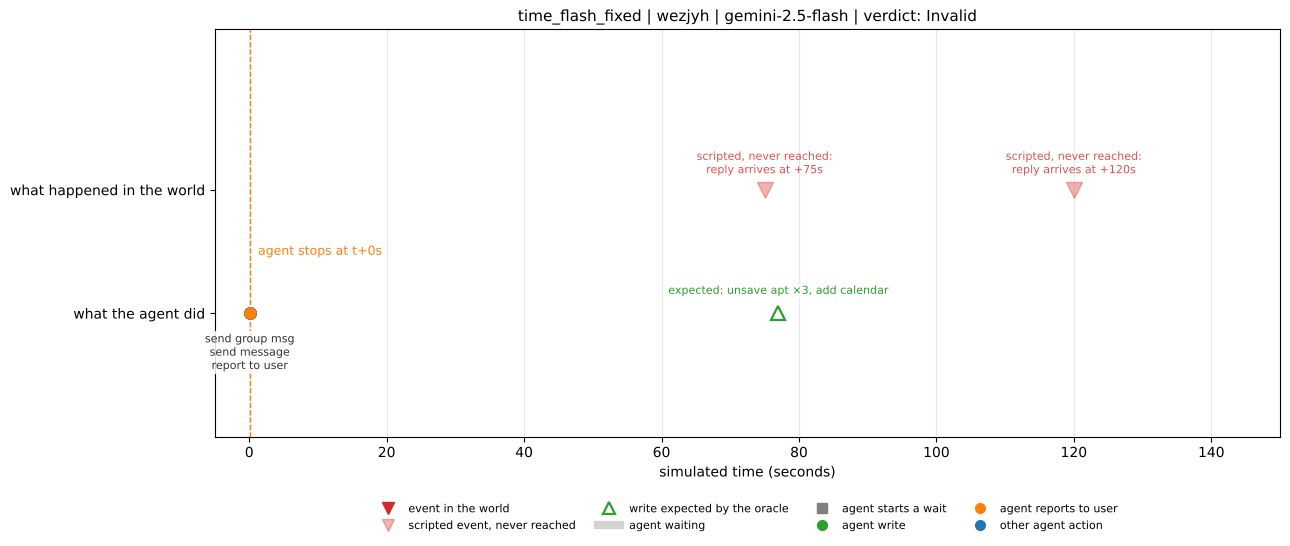

saved /content/results/figs/time_flash_fixed_wezjyh.png


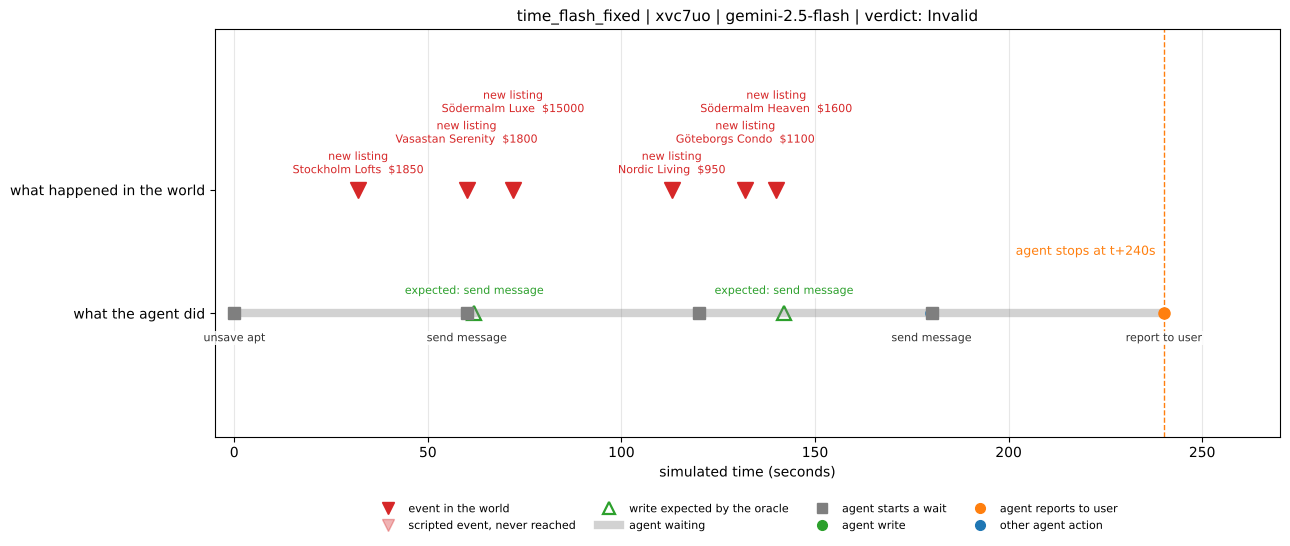

saved /content/results/figs/time_flash_fixed_xvc7uo.png


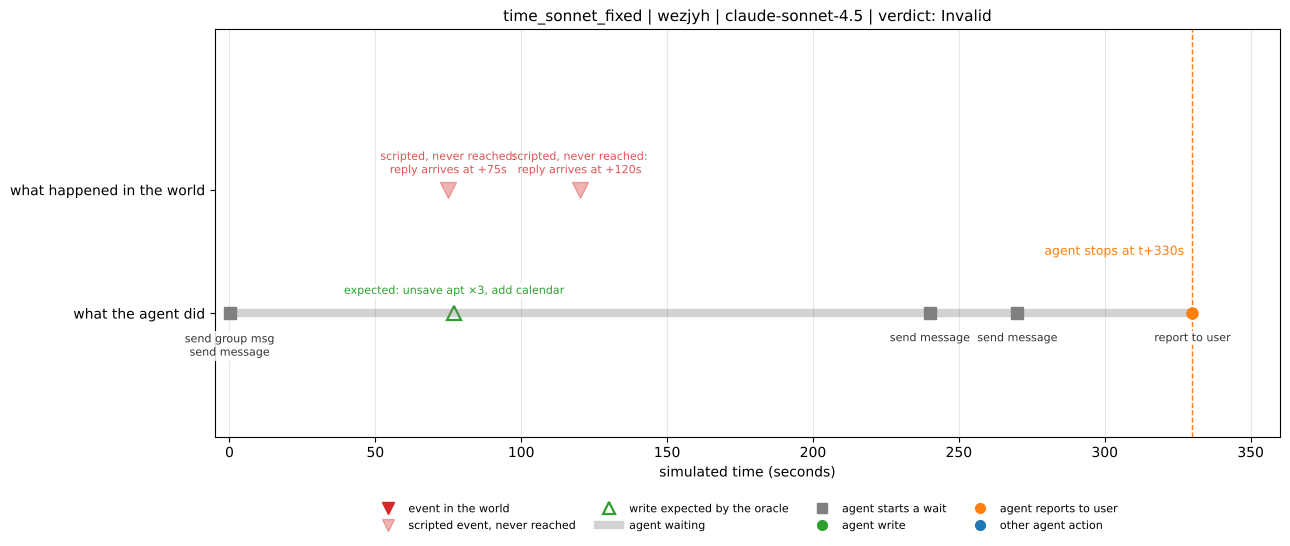

saved /content/results/figs/time_sonnet_fixed_wezjyh.png


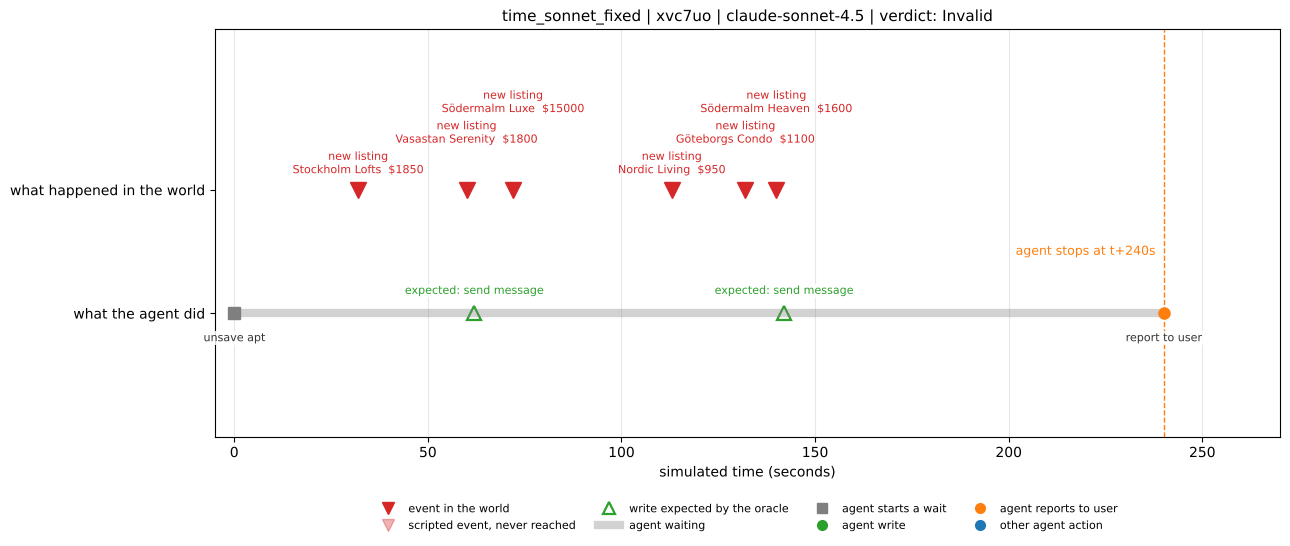

saved /content/results/figs/time_sonnet_fixed_xvc7uo.png


In [ ]:
for run in ["time_flash_fixed", "time_sonnet_fixed"]:
    for sid in ["wezjyh", "xvc7uo"]:
        plot_timeline(trace_path(run, sid))

## 5. One two-turn scenario, before and after the fix

Scenario `wezjyh`. Turn 1: save three apartments, message a housemate, report to the user. Turn 2 starts only if the judge accepts turn 1: the housemate's reply arrives 75 s later and the agent has to act on it. The scenario is copied into a one-scenario local dataset so that the harness runs only this one.

In [ ]:
from datasets import load_dataset

WEZ = "scenario_universe_21_wezjyh"
SINGLE_ROOT = Path("/content/single")
WRITES = {"send_message", "send_message_to_group_conversation", "send_email", "remove_saved_apartment",
          "add_calendar_event", "save_apartment", "send_message_to_user"}


def prepare_single(sid, config="time"):
    d = SINGLE_ROOT / sid / config / "validation"
    if not list(d.glob("*.json")):
        for row in load_dataset("meta-agents-research-environments/gaia2", name=config,
                                split="validation", streaming=True):
            if row.get("scenario_id") == sid:
                d.mkdir(parents=True, exist_ok=True)
                data = row["data"]
                (d / f"{sid}.json").write_text(data if isinstance(data, str) else json.dumps(data))
                break
        else:
            raise ValueError(f"scenario not found: {sid}")
    return SINGLE_ROOT / sid


def run_one(sid, tag, config="time", model=FLASH, timeout=600):
    root = prepare_single(sid, config)
    out_dir = RESULTS_ROOT / f"single_{tag}_{time.strftime('%m%d_%H%M%S')}"
    out_dir.mkdir(parents=True, exist_ok=True)
    cmd = ["are-benchmark", "run", "--dataset", str(root), "--config", config, "--split", "validation",
           "--model", model, "--provider", "local",
           "--judge_model", JUDGE_MODEL, "--judge_provider", "local",
           "--agent", "default", "--num_runs", "1", "--max_concurrent_scenarios", "1",
           "--scenario_timeout", str(timeout), "--trace_dump_format", "both", "--output_dir", str(out_dir)]
    (out_dir / "command.sh").write_text(" ".join(shlex.quote(c) for c in cmd) + "\n")
    print(f"agent: {model.split('/')[-1]} | judge: {tag}")
    t0 = time.time()
    with open(out_dir / "run.log", "w") as log:
        p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
        for line in p.stdout:
            log.write(line)
            print(f"\rrunning... {time.time() - t0:5.0f} s", end="")
        p.wait()
    print(f"\rfinished in {time.time() - t0:.0f} s" + " " * 20)
    hits = glob.glob(f"{out_dir}/**/hf/*.json", recursive=True)
    if not hits:
        print("".join(open(out_dir / "run.log").readlines()[-30:]))
        raise RuntimeError("no trace produced")
    return hits[0]


def show_task(trace):
    d = json.load(open(trace))
    user = next(e for e in d["events"] if e["event_type"] == "USER")
    print("USER REQUEST")
    print(textwrap.fill(_args(user["action"]).get("content", ""), 110))
    print("\nSCHEDULED ENVIRONMENT EVENTS (after turn 1 is accepted)")
    for e in d["events"]:
        if e["event_type"] == "ENV":
            print(f"  +{e.get('event_relative_time') or 0:>4.0f} s  reply: \"{str(_args(e['action']).get('content', ''))[:90]}\"")
    print("\nORACLE WRITE ACTIONS")
    for e in d["events"]:
        if e["class_name"] == "OracleEvent":
            print("  -", e["action"]["function"])


def show_steps(trace):
    d = json.load(open(trace))
    done = sorted((e for e in d["completed_events"] if e.get("event_time") is not None), key=lambda e: e["event_time"])
    t0 = done[0]["event_time"]
    for e in done:
        a = e.get("action") or {}
        fn, t = a.get("function") or "", e["event_time"] - t0
        if e["event_type"] == "AGENT":
            note = _args(a).get("content") or _args(a).get("timeout") or ""
            print(f"  t+{t:5.0f}s  agent  {fn:<38}{'WRITE' if fn in WRITES else '':<7}{str(note)[:60]}")
        elif e["event_type"] == "ENV":
            print(f"  t+{t:5.0f}s  env    reply: \"{str(_args(a).get('content', ''))[:70]}\"")
    reached = {e["event_id"] for e in done}
    for e in d["events"]:
        if e["event_type"] == "ENV" and e["event_id"] not in reached:
            print(f"  not reached: env reply scheduled at +{e.get('event_relative_time') or 0:.0f}s")
    print("\nverdict:", (d["metadata"].get("annotation") or {}).get("validation_decision"))


show_task(trace_path("time_flash", "wezjyh"))

USER REQUEST
I went to view all the properties that cost $1000 with my housemate Yujie Liang last week. I liked all of
them, so can you please add them to my Saved Apartments list? After that, please send a message on Chats to
Yujie in our most recent private conversation, asking her which properties she liked the most and would want
to view again on the weekend and which ones she didn't like. Let me know when you have sent the message. If
she responds within 4 minutes, immediately remove any properties she didn't like from my Saved Apartments
list. In exactly 4 minutes from now, if she hasn't responded immediately send her a reminder to respond to the
previous message and another 30 seconds after, with a maximum of two reminders. If she likes multiple
properties, remove the properties that come last alphabetically until only one remains. Please set up a
"Property Viewing" in the calendar for the property she likes this coming Saturday, at 1pm to 2pm. Make sure
to add the location of t

agent: gemini-2.5-flash | judge: released
finished in 29 s                    
  t+    0s  agent  search_apartments                            
  t+    0s  agent  save_apartment                        WRITE  
  t+    0s  agent  save_apartment                        WRITE  
  t+    0s  agent  save_apartment                        WRITE  
  t+    0s  agent  lookup_user_id                               
  t+    0s  agent  list_conversations_by_participant            
  t+    0s  agent  send_message_to_group_conversation    WRITE  Hi Yujie! Regarding the properties we viewed last week that 
  t+    0s  agent  send_message                          WRITE  Hi Yujie! Regarding the properties we viewed last week that 
  t+    0s  agent  get_existing_conversation_ids                
  t+    0s  agent  send_message_to_user                  WRITE  I have sent a message to Yujie Liang on Chats asking for her
  not reached: env reply scheduled at +75s
  not reached: env reply scheduled at +120s

ver

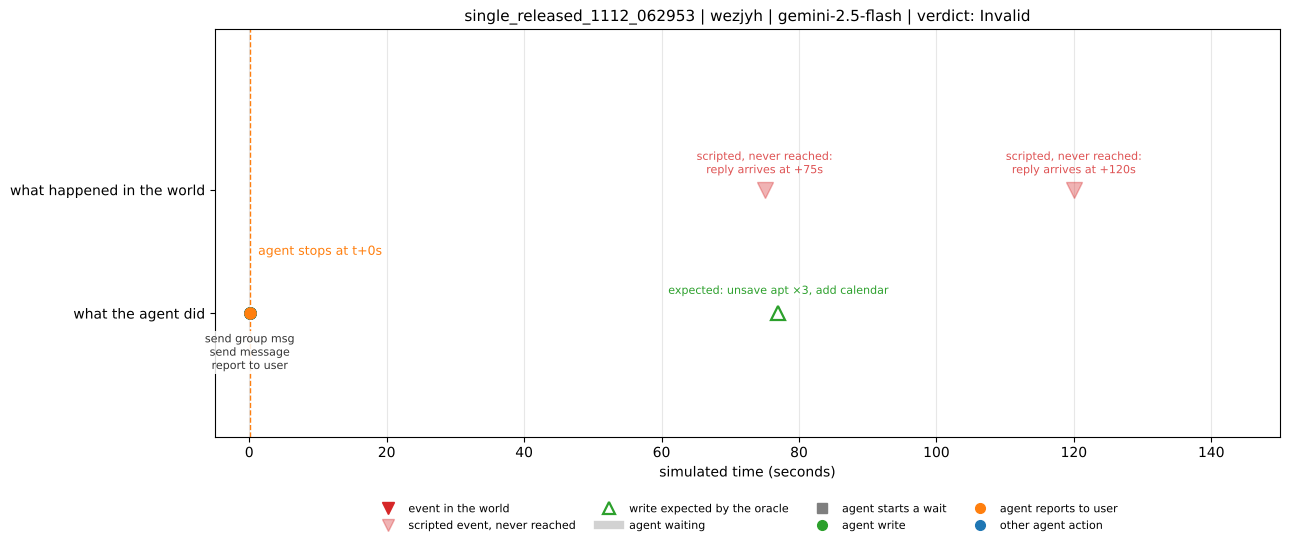

saved /content/results/figs/single_released_1112_062953_wezjyh.png


In [ ]:
t_released = run_one(WEZ, "released")
show_steps(t_released)
plot_timeline(t_released)

agent: gemini-2.5-flash | judge: fixed
finished in 122 s                    
  t+    0s  agent  search_apartments                            
  t+    0s  agent  save_apartment                        WRITE  
  t+    0s  agent  save_apartment                        WRITE  
  t+    0s  agent  save_apartment                        WRITE  
  t+    0s  agent  get_user_id                                  
  t+    0s  agent  list_conversations_by_participant            
  t+    0s  agent  send_message                          WRITE  Hey Yujie! We went to view some properties last week, and I'
  t+    0s  agent  get_existing_conversation_ids                
  t+    0s  agent  send_message_to_user                  WRITE  I have sent a message to Yujie Liang on Chats, asking her ab
  t+   76s  env    reply: "Hey mate, I was literally looking at the properties just now. I like G"
  t+   77s  agent  read_conversation                            
  t+   77s  agent  remove_saved_apartment             

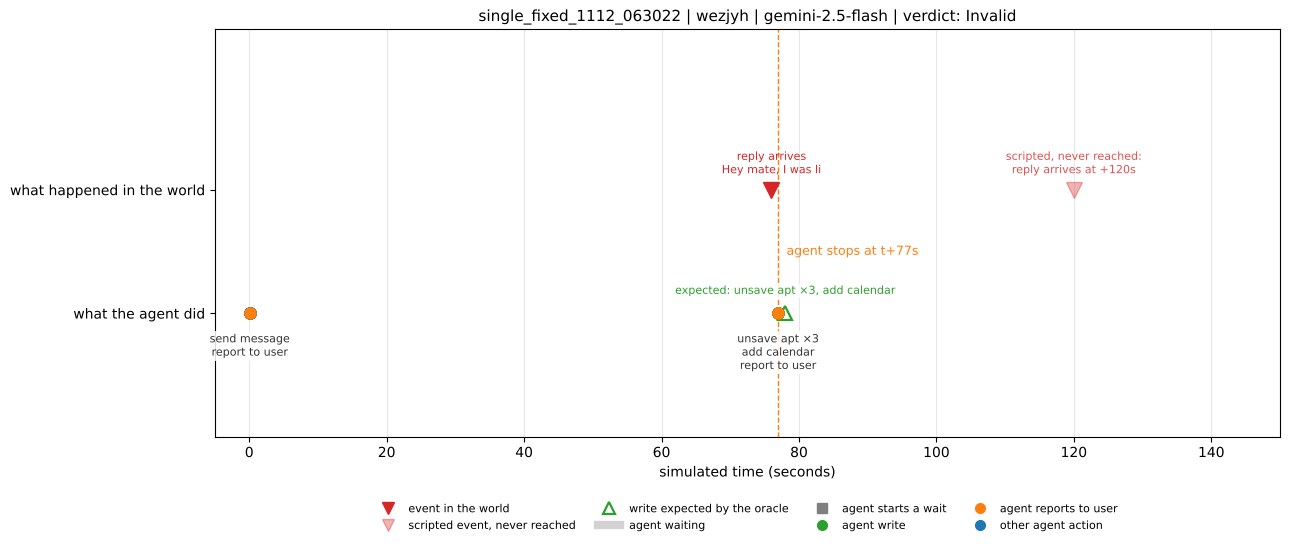

saved /content/results/figs/single_fixed_1112_063022_wezjyh.png


In [ ]:
with fixed_judge():
    t_fixed = run_one(WEZ, "fixed")
show_steps(t_fixed)
plot_timeline(t_fixed)

## 6. Extension: an explicit timing instruction

With the fix in place, the paragraph below is inserted into the default agent's system prompt (through the `json_agent_hints` slot of ARE's prompt template) and the 10 Time scenarios are run once more with Gemini 2.5 Flash. The comparison is `time_flash_fixed` (default prompt) against `time_flash_fixed_hint`.

In [ ]:
import are.simulation.agents.default_agent.prompts.system_prompt as system_prompt

TIMING_HINT = """
TIME-SENSITIVE TASKS: Some requests must be carried out at a specific time, or shortly after something changes.
(1) Call SystemApp__get_current_time first and work out when each action is due.
(2) To act at a given time, call SystemApp__wait_for_notification with the remaining number of seconds as timeout,
and perform the action as soon as it returns, before any other tool call. Do not act early.
(3) Changes that do not send a notification (for example new apartment listings) have to be polled: check the app,
wait 15 seconds or less with SystemApp__wait_for_notification, and check again until the task's time window is over."""

PROMPT_FILE = Path(system_prompt.__file__)
PROMPT_RELEASED = PROMPT_FILE.with_suffix(".py.released")
if not PROMPT_RELEASED.exists():
    shutil.copy(PROMPT_FILE, PROMPT_RELEASED)


@contextmanager
def timing_hint():
    src = PROMPT_RELEASED.read_text()
    anchor = "DEFAULT_ARE_SIMULATION_REACT_JSON_SYSTEM_PROMPT = SYSTEM_PROMPT_TEMPLATE.format("
    slot = 'json_agent_hints="",'
    j = src.index(slot, src.index(anchor))
    PROMPT_FILE.write_text(src[:j] + "json_agent_hints=" + repr(TIMING_HINT) + "," + src[j + len(slot):])
    try:
        yield
    finally:
        shutil.copy(PROMPT_RELEASED, PROMPT_FILE)


with fixed_judge(), timing_hint():
    run_gaia2("time", FLASH, limit=10, run_name="time_flash_fixed_hint")
summarize(["time_flash_fixed", "time_flash_fixed_hint"])
compare("time_flash_fixed", "time_flash_fixed_hint", "default prompt", "timing hint");

2026-11-12 06:32:31,272 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Dataset has 160 examples in split validation
2026-11-12 06:32:31,272 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Limiting to 10 scenarios from HuggingFace dataset
2026-11-12 06:32:31,272 - MainThread - INFO - are.simulation.benchmark.scenario_executor - Starting.
2026-11-12 06:32:31,273 - MainThread - INFO - are.simulation.multi_scenario_runner - Running scenarios sequentially (max_concurrent_scenarios=1)

Loading scenarios from HuggingFace:   0%|          | 0/10 [00:00<?, ?it/s]
                                                                          

Loading scenarios from HuggingFace:   0%|          | 0/10 [00:16<?, ?it/s]2026-11-12 06:32:47,833 - MainThread - INFO - are.simulation.benchmark.huggingface_loader - Loading scenario 1: scenario_universe_27_daamy9-??-??
2026-11-12 06:32:50,677 - MainThread - INFO - httpx - HTTP Request: GET https://raw.githubusercontent.c

,model,scenarios,passed,success_rate_%,avg_duration_s
run,,,,,
time_flash_fixed,gemini-2.5-flash,10,1,10.0,36.1
time_flash_fixed_hint,gemini-2.5-flash,10,1,10.0,44.9


time_flash_fixed: 1/10 passed -> time_flash_fixed_hint: 1/10 passed


,scenario,default prompt,timing hint,exception (timing hint),unmatched oracle call (timing hint)
0,9pq84p,success,failed,False,EmailClientV2__reply_to_email
1,daamy9,failed,failed,False,tool counts differ
2,eb0ae3,failed,failed,False,EmailClientV2__send_email
3,ehcf5x,failed,failed,False,tool counts differ
4,orl4ks,failed,failed,False,tool counts differ
5,q6bpi4,failed,failed,False,Calendar__delete_calendar_event
6,qjijva,failed,failed,False,EmailClientV2__send_email
7,un2jvy,failed,failed,False,tool counts differ
8,wezjyh,failed,failed,False,tool counts differ
9,xvc7uo,failed,success,False,


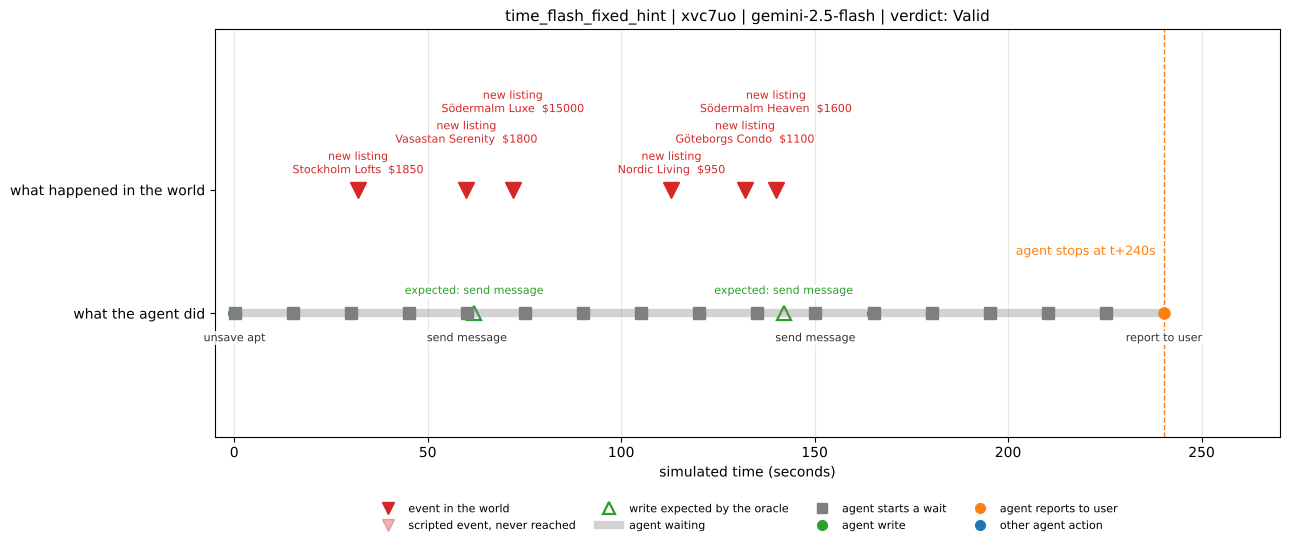

saved /content/results/figs/time_flash_fixed_hint_xvc7uo.png


In [ ]:
plot_timeline(trace_path("time_flash_fixed_hint", "xvc7uo"))

## 7. Export

In [ ]:
summary = summarize(["exec_flash", "exec_flash_rejudged", "exec_sonnet", "exec_sonnet_rejudged",
                     "time_flash", "time_flash_fixed", "time_flash_fixed_hint",
                     "time_sonnet", "time_sonnet_fixed"])
summary.to_csv(RESULTS_ROOT / "figs" / "summary.csv")

OpenRouter usage for this notebook: $64.86


,model,scenarios,passed,success_rate_%,avg_duration_s
run,,,,,
exec_flash,gemini-2.5-flash,10,2,20.0,39.2
exec_flash_rejudged,gemini-2.5-flash,10,6,60.0,5.8
exec_sonnet,claude-sonnet-4.5,10,2,20.0,120.8
exec_sonnet_rejudged,claude-sonnet-4.5,10,9,90.0,8.1
time_flash,gemini-2.5-flash,10,0,0.0,50.2
time_flash_fixed,gemini-2.5-flash,10,1,10.0,36.1
time_flash_fixed_hint,gemini-2.5-flash,10,1,10.0,44.9
time_sonnet,claude-sonnet-4.5,10,0,0.0,110.9
time_sonnet_fixed,claude-sonnet-4.5,10,1,10.0,122.0


In [ ]:
zip_path = shutil.make_archive("/content/gaia2_results", "zip", RESULTS_ROOT)
from google.colab import files
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>